In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st

df = pd.read_csv("./data/cleaned/blood_orders_cleaned.csv")

print(df.head())

   id  hospital_id  centre_id  ordered_at blood_type  component  urgency  \
0   1            5          1  2025-03-13         O+  Red Cells  Routine   
1   2            8          2  2025-03-26         O-  Red Cells   Urgent   
2   3            9          4  2025-04-16         O+  Platelets  Routine   
3   4            9          1  2025-04-26         A+  Red Cells  Routine   
4   5            6          3  2025-03-01        AB+  Red Cells  Routine   

   units_requested  units_issued  
0                1             1  
1                5             2  
2                1             1  
3                2             1  
4                3             1  


## Blood Group

In [13]:

blood_group_chart = df.groupby("blood_type")[["units_requested", "units_issued"]].sum()

fig, ax = plt.subplots(figsize=(8, 5))
blood_group_chart.plot(kind="bar", ax=ax)

ax.set_title("Demand by blood group")
ax.set_xlabel("Blood group")
ax.set_ylabel("Units")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

plt.tight_layout()
st.pyplot(fig) 

2026-11-01 16:05:02.650 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-01 16:05:02.824 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-01 16:05:02.825 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-01 16:05:02.825 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


DeltaGenerator()

## Component

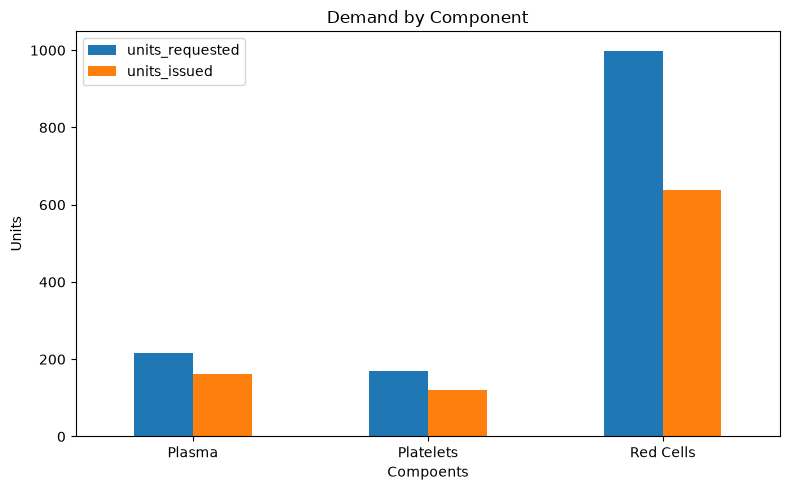

In [6]:
component_grp_chart =  df.groupby("component")[["units_requested", "units_issued"]].sum()

component_grp_chart.plot(kind='bar', figsize=(8,5))
plt.title("Demand by Component")
plt.xlabel("Compoents")
plt.ylabel("Units")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Hospital

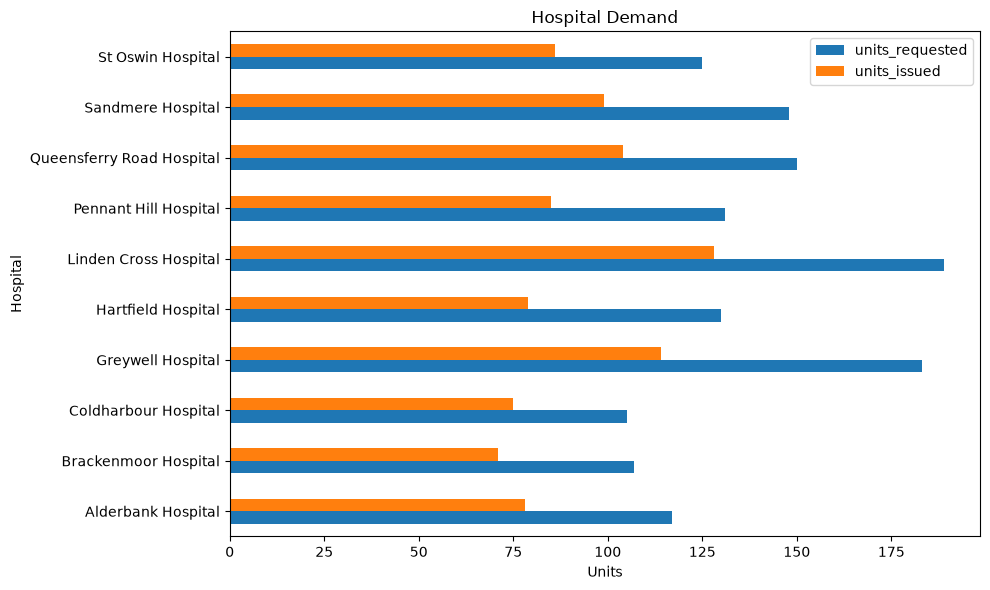

In [7]:
hospital_IDs = pd.read_csv('./data/cleaned/hospitals_cleaned.csv')

df_named = df.merge(hospital_IDs[["id", "name"]], left_on="hospital_id", right_on="id")

hospital_demands = df_named.groupby("name")[["units_requested", "units_issued"]].sum()

hospital_demands.plot(kind='barh', figsize=(10, 6))
plt.title("Hospital Demand")
plt.xlabel("Units")
plt.ylabel("Hospital")
plt.tight_layout()
plt.show()

## Date

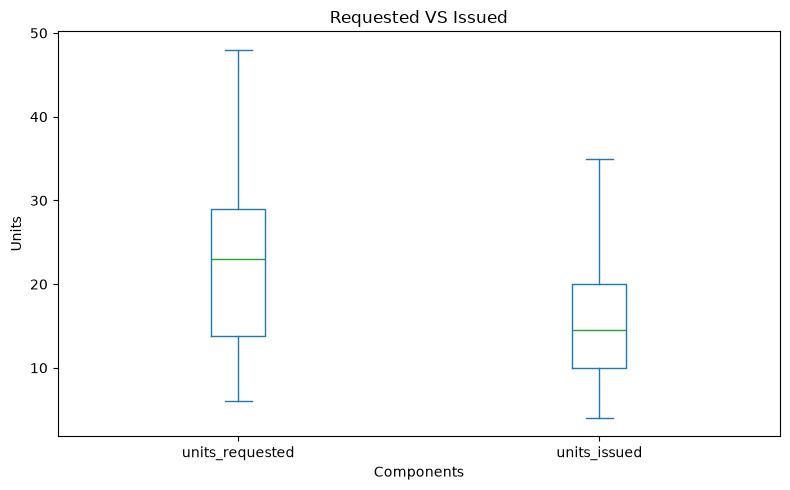

In [8]:
group_date = df.groupby("ordered_at")[["units_requested", "units_issued"]].sum()

group_date.plot(kind='box', figsize=(8,5))
plt.title("Requested VS Issued")
plt.xlabel("Components")
plt.ylabel("Units")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## there are 2 outliers

# <span style="color:Green;">**Summary**</span>
## Blood
Blood Group: *O+ and A+* has the most requested
Supply Gap: units requested consistently exceeds unites issued (shortage)
Lowest Request Blood: *AB- and B- AB+*
## Component
Red cells dominate: nearly **1000 units requested**, which is higher than plasma and platelets combined
Plasma vs Platelets: Plasma is higher but both are in the *range of 150-200 units*
## Hospital
Top requester: Linden Cross Hospital hwich is almost double Hartield Hospital and also **issued the highest**
Consistency: Every hospital always got less than what they requested
## Date
Volume: The box plot shows that the requested always **get issued less** than what they were **requested**
Median: median reuquest is higher than median (3 units) and is issued at a median of 2

